# One pound sign is a level one header


shift enter is how to run a code cell in Markdown

# A 1D diffusion model

Here we will develop a one dimensional numerical model of diffusion. 
It assumes a constant diffusivity.
It uses a regular grid. 
It has a step function for an intitial profile 
It has fixed boundary conditions 

This is the equation for the diffusion model

$$ \frac{\partial z}{\partial t} = D\frac{\partial^2 z}{\partial x^2} $$

Here, $z$ is elevation, $t$ is time, and $x$ is the spatial dimension, $D$ is the transport-rate coefficient, sometimes called hillslope diffusivity, with dimensions length squared per time. 

The discretized version of the diffusion equation we'll solve with our model is:
$$ z^{t+1}_x = z^t_x + {D \Delta t \over \Delta x^2} (z^t_{x+1} - 2z^t_x + z^t_{x-1}) $$

This is the FTCS scheme you can look up in a textbook (forward in time centered in space)

We'll use 2 libraries, NumPy (for arrays) and Matplotlib (for plots) that aren't a part of the core Python distribution. We use the following nicknames (np and plt) because those are the convention in the language, this is best practice.

In [4]:
import numpy as np
import matplotlib.pyplot as plt # pyplot is a sub section of matplotlib

Start by setting two fixed model parameters - the diffusivity and the size of the model domain. Best practice: Use descriptive variable names, don't just name the variable a single letter. 

In [5]:
D = 100 # diffusivity
Lx = 300 # model domain

Next, we set up the grid using a NumPy array.

In [6]:
dx = 0.5 # grid spacing between grid nodes
x = np.arange(start=0, stop=Lx, step=dx) # x is a numpy 1D array starting at zero, stopping at Lx, with spacing dx. arange is array range
nx = len(x) # number of grid nodes 

Set the initial conditions for the model. The elvation $z$ is a step function with a high value to the left, a low value on the right, and a cliff in the middle of the domain. 

In [9]:
z = np.zeros_like(x) # create elevation values - a numpy array of zeros with the same shape as x, so z is an array of 600 zeros with type "float"
z_left = 500 # the left side of the domain is 500
z_right = 0 # the right side of the domain is 0
z[x<=Lx / 2] = z_left # create the step function: use subscript automation. for values of of z at x that are half of the domain size or less, set them to z_left
z[x > Lx / 2] = z_right # for values of z at x that are greater than half of the domain size, set them to z_right

Plot the initial profile. 

Text(0.5, 1.0, 'Initial hillslope profile')

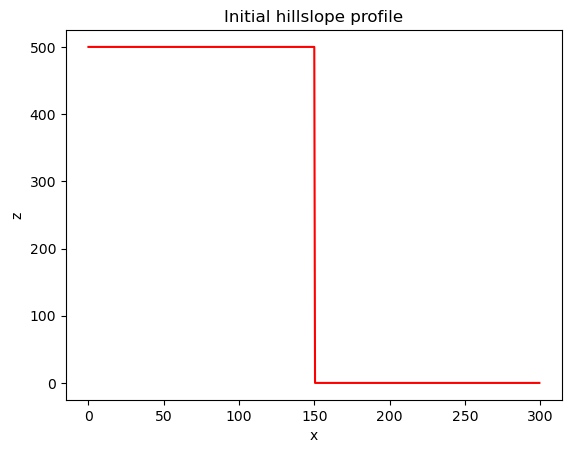

In [11]:
plt.figure() # open figure window
plt.plot(x, z, "r") # plot x vs z in red - the initial profile, a cliff
plt.xlabel("x")
plt.ylabel("z")
plt.title("Initial hillslope profile")


Set up time stepping for the model. Calculate a stable time step from a stability criterion. 

In [12]:
nt = 5000 # number of time steps
dt = 0.5 * dx**2 / D # time step size based on stability criterion for diffusion

Loop over the time steps of the model, solving the diffusion equation using the FTCS scheme described above.
Note the use of array operations on the elevation $z$.
The boundary conditions remain fixed in each time step. 

In [13]:
for t in range(0, nt):
	z[1:-1] += D * dt / dx ** 2 * (z[:-2] - 2*z[1:-1] + z[2:])

Plot the result - we have diffused away the cliff. 

Text(0.5, 1.0, 'Final hillslope profile')

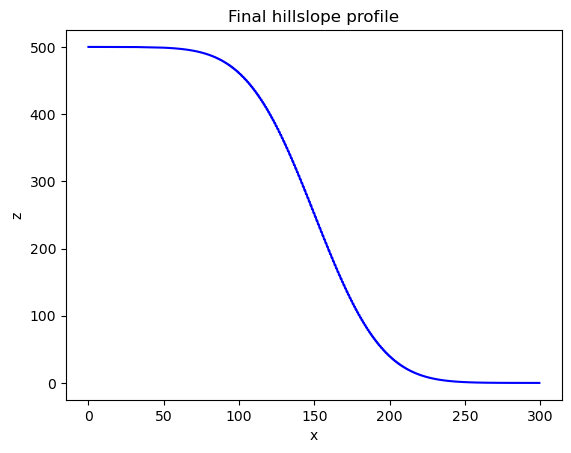

In [14]:
plt.figure() # open figure window
plt.plot(x, z, "b") # plot x vs z in blue - the final profile, after diffusion
plt.xlabel("x")
plt.ylabel("z")
plt.title("Final hillslope profile")